# 01 — Khám phá dữ liệu (EDA): review Điện Máy Xanh

Bước 0.8 trong `PHAN_TICH_DE.md`. Notebook chỉ **đọc** dữ liệu và kết quả đã có (không train mô hình), mọi con số in ra từ code.

| Mục | Nội dung | Slide |
|---|---|---|
| 1 | Thống kê crawl và làm sạch | Ch.2 §2.1 (làm sạch, loại nhiễu); Ch.5 (cosine similarity lọc gần trùng) |
| 2 | Phân bố số sao và phân bố nhãn | Ch.3 (dữ liệu có nhãn, mất cân bằng → macro-F1); Ch.6 (ví dụ "mô hình lười", trích nhẹ) |
| 3 | Số review theo ngành hàng; độ dài review theo nhãn | Ch.3 (bước tìm hiểu dữ liệu trước khi trích đặc trưng) |
| 4 | Top từ/bigram đặc trưng mỗi lớp (chỉ trên TRAIN) | Ch.2 §2.2 (tách từ), §2.3 (stopword); Ch.3 (TF-IDF, n-gram) |
| 5 | Nhãn chữ theo từng mức sao | Ch.3 (nhãn huấn luyện); đo nhiễu nhãn sao **[Ngoài slide]** |

Quy ước nhãn: **nhãn sao** = 1–2★ Negative, 3★ Neutral, 4–5★ Positive (đối chứng, thí nghiệm A); **nhãn chữ** = nhãn theo nội dung chữ do LLM gán theo `docs/HUONG_DAN_GAN_NHAN.md` (train/val, thí nghiệm B); **nhãn gold** = nhãn tập test (LLM gán, người duyệt).

Không làm K-means và word cloud (đã chốt). Hình lưu ở `results/figures/eda_*.png`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.features import tfidf  # same TF-IDF settings as the models (token pattern, sublinear tf)

DATA, RES = ROOT / "data", ROOT / "results"
FIG = RES / "figures"
FIG.mkdir(parents=True, exist_ok=True)
LABELS = ["Negative", "Neutral", "Positive"]
# dataviz reference palette: categorical slots 1-3 in fixed order (validated on the light surface;
# contrast WARN on aqua -> every bar carries a direct value label)
COL = {"Negative": "#2a78d6", "Neutral": "#eb6834", "Positive": "#1baf7a"}
BLUE, INK, INK2, GRID, SURF = "#2a78d6", "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF, "savefig.dpi": 150,
    "savefig.bbox": "tight", "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "xtick.color": INK2,
    "ytick.color": INK2, "axes.titlecolor": INK, "axes.titlelocation": "left", "axes.titlesize": 12,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 10,
    "xtick.major.size": 0, "ytick.major.size": 0})


def save(fig, name: str) -> None:
    fig.savefig(FIG / f"eda_{name}.png")
    plt.show()


def grid(ax, axis: str = "x") -> None:
    getattr(ax, f"{axis}axis").grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


clean_stats = json.loads((RES / "metrics" / "clean_stats.json").read_text(encoding="utf-8"))
clean = pd.read_csv(DATA / "interim" / "reviews_clean.csv")
train = pd.read_csv(DATA / "processed" / "train.csv")
val = pd.read_csv(DATA / "processed" / "val.csv")
test = pd.read_csv(DATA / "processed" / "test.csv")
pool = pd.concat([train.assign(split="train"), val.assign(split="val")], ignore_index=True)
print(f"clean: {len(clean)} | train: {len(train)} | val: {len(val)} | test (gold): {len(test)}")

clean: 6540 | train: 5120 | val: 904 | test (gold): 500


## 1. Thống kê crawl và làm sạch  (Ch.2 §2.1; Ch.5)

Thứ tự lọc trong `src/clean_label.py`: bỏ review rỗng → bỏ review < 3 từ → bỏ review không phải tiếng Việt → bỏ phản hồi của nhân viên → bỏ trùng y hệt → bỏ **gần trùng** bằng cosine similarity trên TF-IDF > 0,9 (Ch.5). Bỏ gần trùng chạy trên toàn bộ dữ liệu **trước** khi lấy mẫu tập gold, nên giữa test và train không còn cặp câu gần trùng.

,Bước,Số bị loại,Còn lại
0,Thô (sau crawl),NaN,9481
1,Rỗng,17.0,9464
2,Dưới 3 từ,1976.0,7488
3,Không phải tiếng Việt,3.0,7485
4,Phản hồi nhân viên,0.0,7485
5,Trùng y hệt,690.0,6795
6,"Gần trùng (cosine TF-IDF > 0,9)",255.0,6540


Sạch: 6540 review, 19 ngành hàng, 72 sản phẩm; trung vị 13 từ/review
Tập gold (test): 500 review (71 sản phẩm, tối đa 15/sản phẩm) | pool train+val trước khi loại câu trùng test: 6040


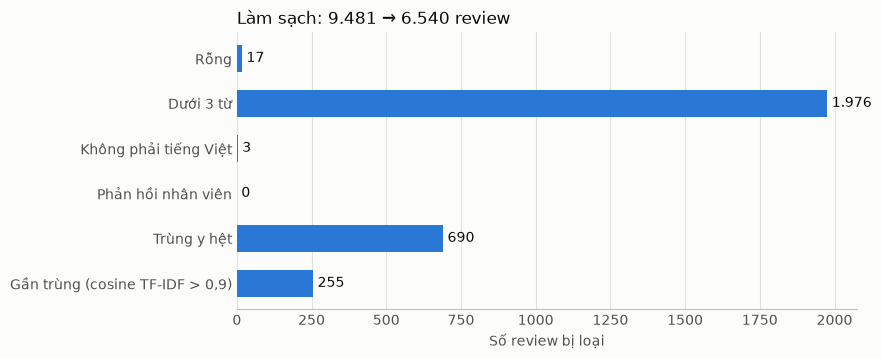

In [2]:
steps = [("Rỗng", "drop_empty"), ("Dưới 3 từ", "drop_short_lt3_words"),
         ("Không phải tiếng Việt", "drop_non_vietnamese"), ("Phản hồi nhân viên", "drop_staff_reply"),
         ("Trùng y hệt", "drop_exact_dup"), ("Gần trùng (cosine TF-IDF > 0,9)", "drop_near_dup_cos_gt_0.9")]
left, rows = clean_stats["raw"], [("Thô (sau crawl)", None, clean_stats["raw"])]
for name, key in steps:
    left -= clean_stats[key]
    rows.append((name, clean_stats[key], left))
flow = pd.DataFrame(rows, columns=["Bước", "Số bị loại", "Còn lại"])
assert left == clean_stats["clean"], "cleaning steps do not add up"
display(flow)
print(f"Sạch: {clean_stats['clean']} review, {clean_stats['n_categories']} ngành hàng, {clean_stats['n_products']} sản phẩm; "
      f"trung vị {clean_stats['words_median']:.0f} từ/review")
print(f"Tập gold (test): {clean_stats['gold']} review ({clean_stats['gold_n_products']} sản phẩm, tối đa "
      f"{clean_stats['gold_max_per_product']}/sản phẩm) | pool train+val trước khi loại câu trùng test: {clean_stats['pool_after_gold']}")

d = flow.dropna().iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(d["Bước"], d["Số bị loại"], height=0.6, color=BLUE)
for y, v in enumerate(d["Số bị loại"]):
    ax.text(v + 15, y, f"{int(v):,}".replace(",", "."), va="center", color=INK)
grid(ax)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Số review bị loại")
ax.set_title(f"Làm sạch: {clean_stats['raw']:,} → {clean_stats['clean']:,} review".replace(",", "."))
save(fig, "cleaning")

## 2. Phân bố số sao và phân bố nhãn  (Ch.3; Ch.6)

Lưu ý: crawl có giới hạn theo sao (lấy hết 1–3★, giới hạn số review 4★ và 5★ mỗi sản phẩm) để có đủ review tiêu cực và trung tính, nên phân bố sao dưới đây **không** phải phân bố thật trên ĐMX (thực tế phần lớn là 5★).

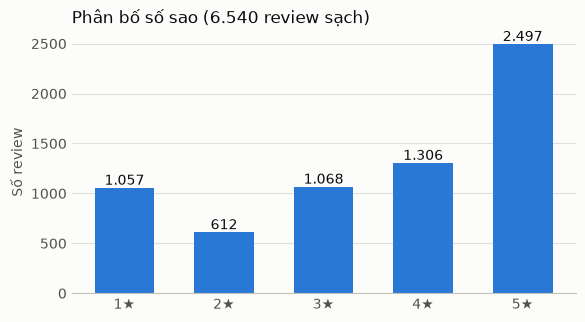

,1,2,3,4,5
%,16.2,9.4,16.3,20.0,38.2


In [3]:
stars = pd.Series(clean_stats["clean_by_star"]).rename(index=int).sort_index()
fig, ax = plt.subplots(figsize=(6.5, 3.4))
ax.bar([f"{s}★" for s in stars.index], stars.values, width=0.6, color=BLUE)
for x, v in enumerate(stars.values):
    ax.text(x, v + 30, f"{v:,}".replace(",", "."), ha="center", color=INK)
grid(ax, "y")
ax.spines["left"].set_visible(False)
ax.set_ylabel("Số review")
ax.set_title(f"Phân bố số sao ({stars.sum():,} review sạch)".replace(",", "."))
save(fig, "stars")
display((stars / stars.sum() * 100).round(1).rename("%").to_frame().T)

,Nhãn sao (train+val),Nhãn chữ (train),Nhãn chữ (val),Nhãn gold (test)
Negative,1499,2024,343,289
Neutral,917,400,65,47
Positive,3608,2696,496,164


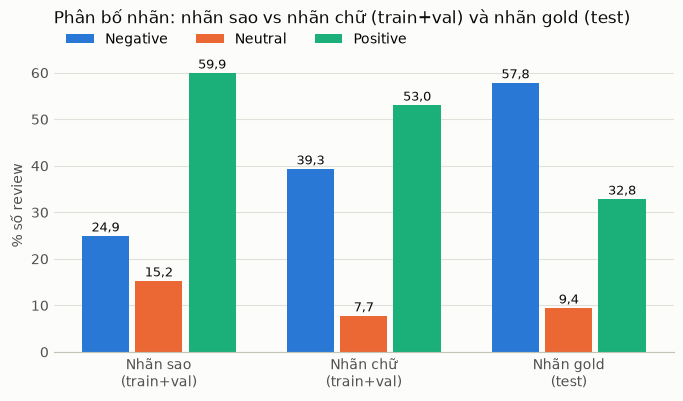

In [4]:
dist = pd.DataFrame({
    "Nhãn sao\n(train+val)": pool["label_star"].value_counts(normalize=True),
    "Nhãn chữ\n(train+val)": pool["label_text"].value_counts(normalize=True),
    "Nhãn gold\n(test)": test["label"].value_counts(normalize=True),
}).reindex(LABELS) * 100
counts = pd.DataFrame({"Nhãn sao (train+val)": pool["label_star"].value_counts(),
                       "Nhãn chữ (train)": train["label_text"].value_counts(),
                       "Nhãn chữ (val)": val["label_text"].value_counts(),
                       "Nhãn gold (test)": test["label"].value_counts()}).reindex(LABELS)
display(counts)

x, w = np.arange(len(dist.columns)), 0.26
fig, ax = plt.subplots(figsize=(8, 3.8))
for i, lab in enumerate(LABELS):
    xs = x + (i - 1) * w
    ax.bar(xs, dist.loc[lab], w - 0.03, color=COL[lab], label=lab)
    for xi, v in zip(xs, dist.loc[lab]):
        ax.text(xi, v + 1, f"{v:.1f}".replace(".", ","), ha="center", fontsize=9, color=INK)
ax.set_xticks(x, dist.columns)
grid(ax, "y")
ax.spines["left"].set_visible(False)
ax.set_ylabel("% số review")
ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Phân bố nhãn: nhãn sao vs nhãn chữ (train+val) và nhãn gold (test)", pad=26)
save(fig, "label_distribution")

Lớp Neutral là lớp ít nhất ở cả nhãn chữ và nhãn gold. Một mô hình "lười" luôn đoán lớp đông nhất vẫn có accuracy khá cao mà vô dụng (Ch.6), nên bài lấy **macro-F1** làm chỉ số chính (Ch.3: F1 hữu ích khi Precision và Recall lệch nhau). Tập test lấy mẫu phân tầng theo **sao** (nhiều 1–3★ hơn thực tế), nên phân bố nhãn của test khác train/val.

## 3. Số review theo ngành hàng; độ dài review theo nhãn  (Ch.3)

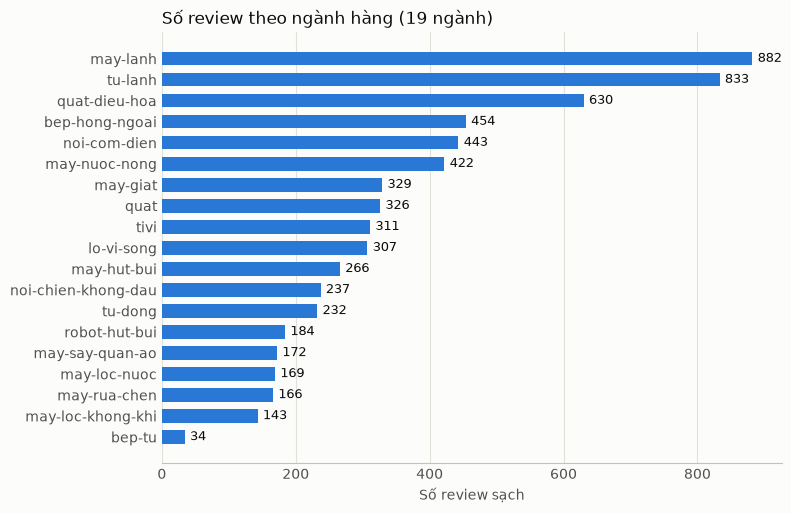

In [5]:
cat = pd.Series(clean_stats["clean_by_category"]).sort_values()
fig, ax = plt.subplots(figsize=(8, 5.6))
ax.barh(cat.index, cat.values, height=0.65, color=BLUE)
for y, v in enumerate(cat.values):
    ax.text(v + 8, y, str(v), va="center", fontsize=9, color=INK)
grid(ax)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Số review sạch")
ax.set_title(f"Số review theo ngành hàng ({len(cat)} ngành)")
save(fig, "categories")

,count,mean,25%,50%,75%,max
label_text,,,,,,
Negative,2367.0,37.4,13.0,24.0,45.0,889.0
Neutral,465.0,17.3,7.0,12.0,21.0,168.0
Positive,3192.0,13.1,5.0,9.0,16.0,492.0


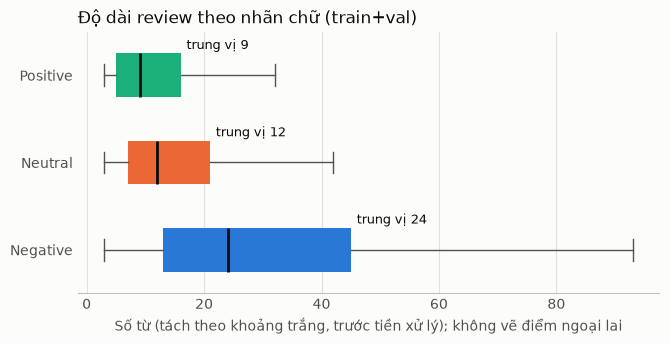

In [6]:
pool["n_words"] = pool["text"].astype(str).str.split().str.len()
length = pool.groupby("label_text")["n_words"].describe(percentiles=[0.25, 0.5, 0.75]).reindex(LABELS)
display(length[["count", "mean", "25%", "50%", "75%", "max"]].round(1))

fig, ax = plt.subplots(figsize=(7.5, 3.4))
data = [pool.loc[pool["label_text"] == lab, "n_words"] for lab in LABELS]
bp = ax.boxplot(data, orientation="horizontal", showfliers=False, widths=0.5, patch_artist=True,
                medianprops={"color": INK, "linewidth": 2}, whiskerprops={"color": INK2},
                capprops={"color": INK2}, boxprops={"linewidth": 0})
for patch, lab in zip(bp["boxes"], LABELS):
    patch.set_facecolor(COL[lab])
for y, lab in enumerate(LABELS, start=1):
    ax.text(length.loc[lab, "75%"] + 1, y + 0.3, f"trung vị {length.loc[lab, '50%']:.0f}", fontsize=9, color=INK)
ax.set_yticks(range(1, 4), LABELS)
grid(ax)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Số từ (tách theo khoảng trắng, trước tiền xử lý); không vẽ điểm ngoại lai")
ax.set_title("Độ dài review theo nhãn chữ (train+val)")
save(fig, "length_by_label")

Review Negative dài hơn hẳn hai lớp kia: người mua chê thường kể lại sự cố, quá trình bảo hành. Review Positive ngắn nhất (nhiều câu chỉ vài chữ như "sản phẩm tốt"). Câu càng ngắn thì càng ít ngữ cảnh, đây là một nguồn lỗi (nhóm "Câu cụt, viết tắt, thiếu ngữ cảnh" trong `results/error_groups.csv`).

## 4. Top từ/bigram đặc trưng mỗi lớp — chỉ tính trên TRAIN  (Ch.2 §2.2–2.3; Ch.3)

Dùng `text_clean` (đã tách từ underthesea, bỏ stopword nhưng **giữ** từ phủ định/mức độ như *không, chưa, rất, nhưng*) và **nhãn chữ** của tập train. Vectorizer TF-IDF n-gram (1,2) giống mô hình (`src/features.py`), `min_df=5`, chỉ `fit` trên train (không dùng val/test).

Điểm đặc trưng của một n-gram cho lớp *c* = TF-IDF trung bình trong lớp *c* − TF-IDF trung bình lớn nhất trong 2 lớp còn lại. Điểm cao nghĩa là n-gram xuất hiện nhiều ở lớp *c* hơn hẳn các lớp khác.

Từ vựng TF-IDF n-gram (1,2), min_df=5, fit trên train: 3162 n-gram


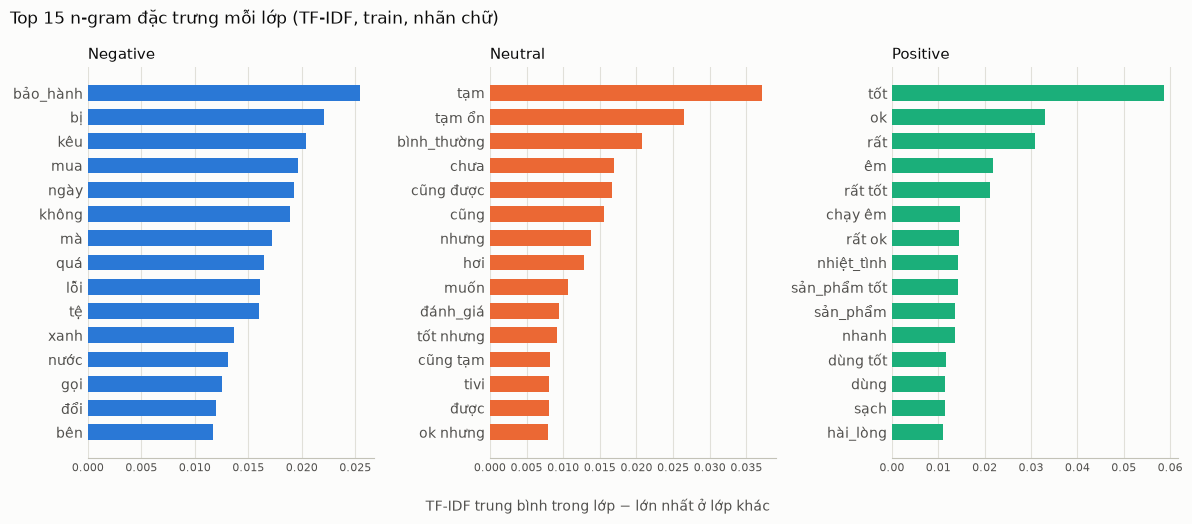

,Negative,Neutral,Positive
hạng,,,
1,quá tệ,tạm ổn,rất tốt
2,điện_máy xanh,cũng được,chạy êm
3,điện máy,tốt nhưng,rất ok
4,bị lỗi,cũng tạm,sản_phẩm tốt
5,rất tệ,ok nhưng,dùng tốt
6,máy xanh,tạm được,sử_dụng tốt
7,kêu to,chưa biết,xài tốt
8,không lạnh,muốn hủy,xài rất
9,mua được,hủy đơn,dùng rất


In [7]:
vec = tfidf(ngram=(1, 2), min_df=5)
X = vec.fit_transform(train["text_clean"].fillna(""))
terms = np.array(vec.get_feature_names_out())
y = train["label_text"].to_numpy()
mean = np.vstack([np.asarray(X[y == lab].mean(axis=0)).ravel() for lab in LABELS])
print(f"Từ vựng TF-IDF n-gram (1,2), min_df=5, fit trên train: {len(terms)} n-gram")

TOP = 15
top, top_bi = {}, {}
for i, lab in enumerate(LABELS):
    score = mean[i] - np.delete(mean, i, axis=0).max(axis=0)
    order = np.argsort(-score)
    top[lab] = pd.DataFrame({"term": terms[order[:TOP]], "score": score[order[:TOP]]})
    bi = [j for j in order if " " in terms[j]][:10]
    top_bi[lab] = terms[bi]

fig, axes = plt.subplots(1, 3, figsize=(12, 5.2))
for ax, lab in zip(axes, LABELS):
    d = top[lab].iloc[::-1]
    ax.barh(d["term"], d["score"], height=0.65, color=COL[lab])
    grid(ax)
    ax.spines["left"].set_visible(False)
    ax.set_title(lab, fontsize=11)
    ax.tick_params(axis="x", labelsize=8)
fig.suptitle("Top 15 n-gram đặc trưng mỗi lớp (TF-IDF, train, nhãn chữ)", x=0.01, ha="left", color=INK, fontsize=12)
fig.supxlabel("TF-IDF trung bình trong lớp − lớn nhất ở lớp khác", color=INK2, fontsize=10)
fig.tight_layout()
save(fig, "top_terms")
display(pd.DataFrame(top_bi).rename_axis("hạng").rename(index=lambda i: i + 1))

Nhận xét (đọc từ hình và bảng trên):
- **Negative**: từ về sự cố và hậu mãi (*bảo_hành, bị, kêu, lỗi, đổi, gọi*), từ mức độ đi với chê (*quá tệ, rất tệ*), và tên cửa hàng (*điện_máy xanh*) vì nhiều review phàn nàn dịch vụ.
- **Neutral**: từ đánh giá vừa phải (*tạm, tạm ổn, bình_thường, cũng được*), từ tương phản (*nhưng, tốt nhưng, ok nhưng*) của câu khen chê lẫn lộn, và *chưa, chưa sử_dụng* (chưa dùng nên chưa đánh giá), *hủy đơn*.
- **Positive**: *tốt, ok, rất, êm, nhiệt_tình, hài_lòng*.
- Các từ *không, chưa, nhưng, rất, quá, bị* nằm trong top đặc trưng. Đây là bằng chứng cho việc **giữ** các từ này khi bỏ stopword (Ch.2 §2.3, danh sách stopword tùy chỉnh qua `resources/keep_words.txt`); bỏ chúng thì "không lạnh" sẽ thành "lạnh". Bigram giữ được cụm phủ định và tương phản (*không lạnh, tốt nhưng*), lý do dùng n-gram (1,2) cho BoW/TF-IDF (Ch.3).

## 5. Nhãn chữ theo từng mức sao  (Ch.3; nhiễu nhãn sao [Ngoài slide])

Đọc từ `results/label_noise_pool.csv` (6.024 review train+val, sinh bởi `python -m src.pool_llm merge`). Mỗi cột là một mức sao, chia theo nhãn chữ. Phần không trùng với nhãn sao chính là "sao nói một đằng, chữ nói một nẻo".

,Negative,Neutral,Positive,n,pct_label_text_differs_from_star
star,,,,,
1,949,4,4,957,0.0084
2,538,0,4,542,0.0074
3,677,168,72,917,0.8168
4,158,200,861,1219,0.2937
5,45,93,2251,2389,0.0578


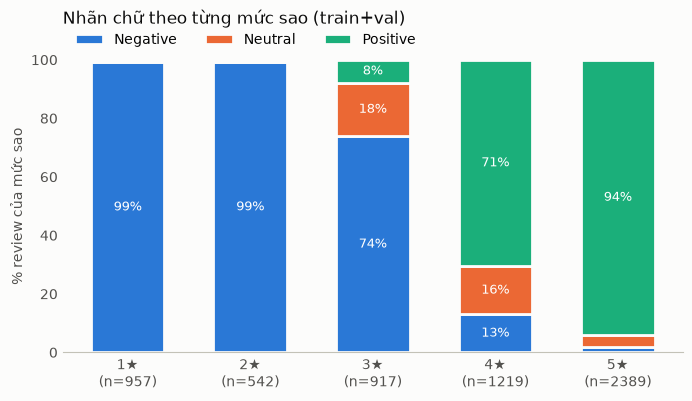

Tỷ lệ nhãn chữ khác nhãn sao theo mức sao (%):
star
1     0.8
2     0.7
3    81.7
4    29.4
5     5.8
Chung: 20.9%


In [8]:
noise = pd.read_csv(RES / "label_noise_pool.csv", index_col="star")
display(noise)
share = noise[LABELS].div(noise["n"], axis=0) * 100

fig, ax = plt.subplots(figsize=(8, 3.8))
bottom = np.zeros(len(share))
xs = [f"{s}★\n(n={n})" for s, n in zip(share.index, noise["n"])]
for lab in LABELS:
    v = share[lab].to_numpy()
    ax.bar(xs, v, 0.6, bottom=bottom, color=COL[lab], label=lab, edgecolor=SURF, linewidth=2)
    for xi, (b, h) in enumerate(zip(bottom, v)):
        if h >= 6:
            ax.text(xi, b + h / 2, f"{h:.0f}%", ha="center", va="center", fontsize=9, color="#ffffff")
    bottom += v
ax.set_ylim(0, 100)
ax.spines["left"].set_visible(False)
ax.set_ylabel("% review của mức sao")
ax.legend(ncol=3, frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("Nhãn chữ theo từng mức sao (train+val)", pad=26)
save(fig, "text_label_by_star")
print("Tỷ lệ nhãn chữ khác nhãn sao theo mức sao (%):")
print((noise["pct_label_text_differs_from_star"] * 100).round(1).to_string())
print(f"Chung: {(pool['label_text'] != pool['label_star']).mean() * 100:.1f}%")

Nhận xét: với 1–2★ nhãn chữ gần như luôn trùng nhãn sao. Lệch nhiều nhất ở **3★**: phần lớn review 3★ có nội dung chê, chỉ một phần nhỏ thật sự trung tính. 4★ lẫn khá nhiều Neutral và Negative. Vì vậy nếu dùng nhãn sao làm nhãn huấn luyện (thí nghiệm A), lớp Neutral chủ yếu là câu chê, mô hình học sai ranh giới; đây là lý do thí nghiệm B gán lại train/val theo nội dung chữ, cùng hướng dẫn với tập gold.

## Tóm tắt
- Dữ liệu sạch nhỏ hơn mục tiêu ban đầu và Neutral là lớp hiếm ở mọi tập → chỉ số chính là macro-F1, có `class_weight` / trọng số lớp khi huấn luyện.
- Từ phủ định, mức độ, tương phản mang nhiều tín hiệu cảm xúc → giữ lại khi bỏ stopword, dùng bigram.
- Nhãn sao lệch nội dung nhiều nhất ở 3★ và 4★ → dùng nhãn chữ cho train/val (B); nhãn sao chỉ còn làm đối chứng (A).